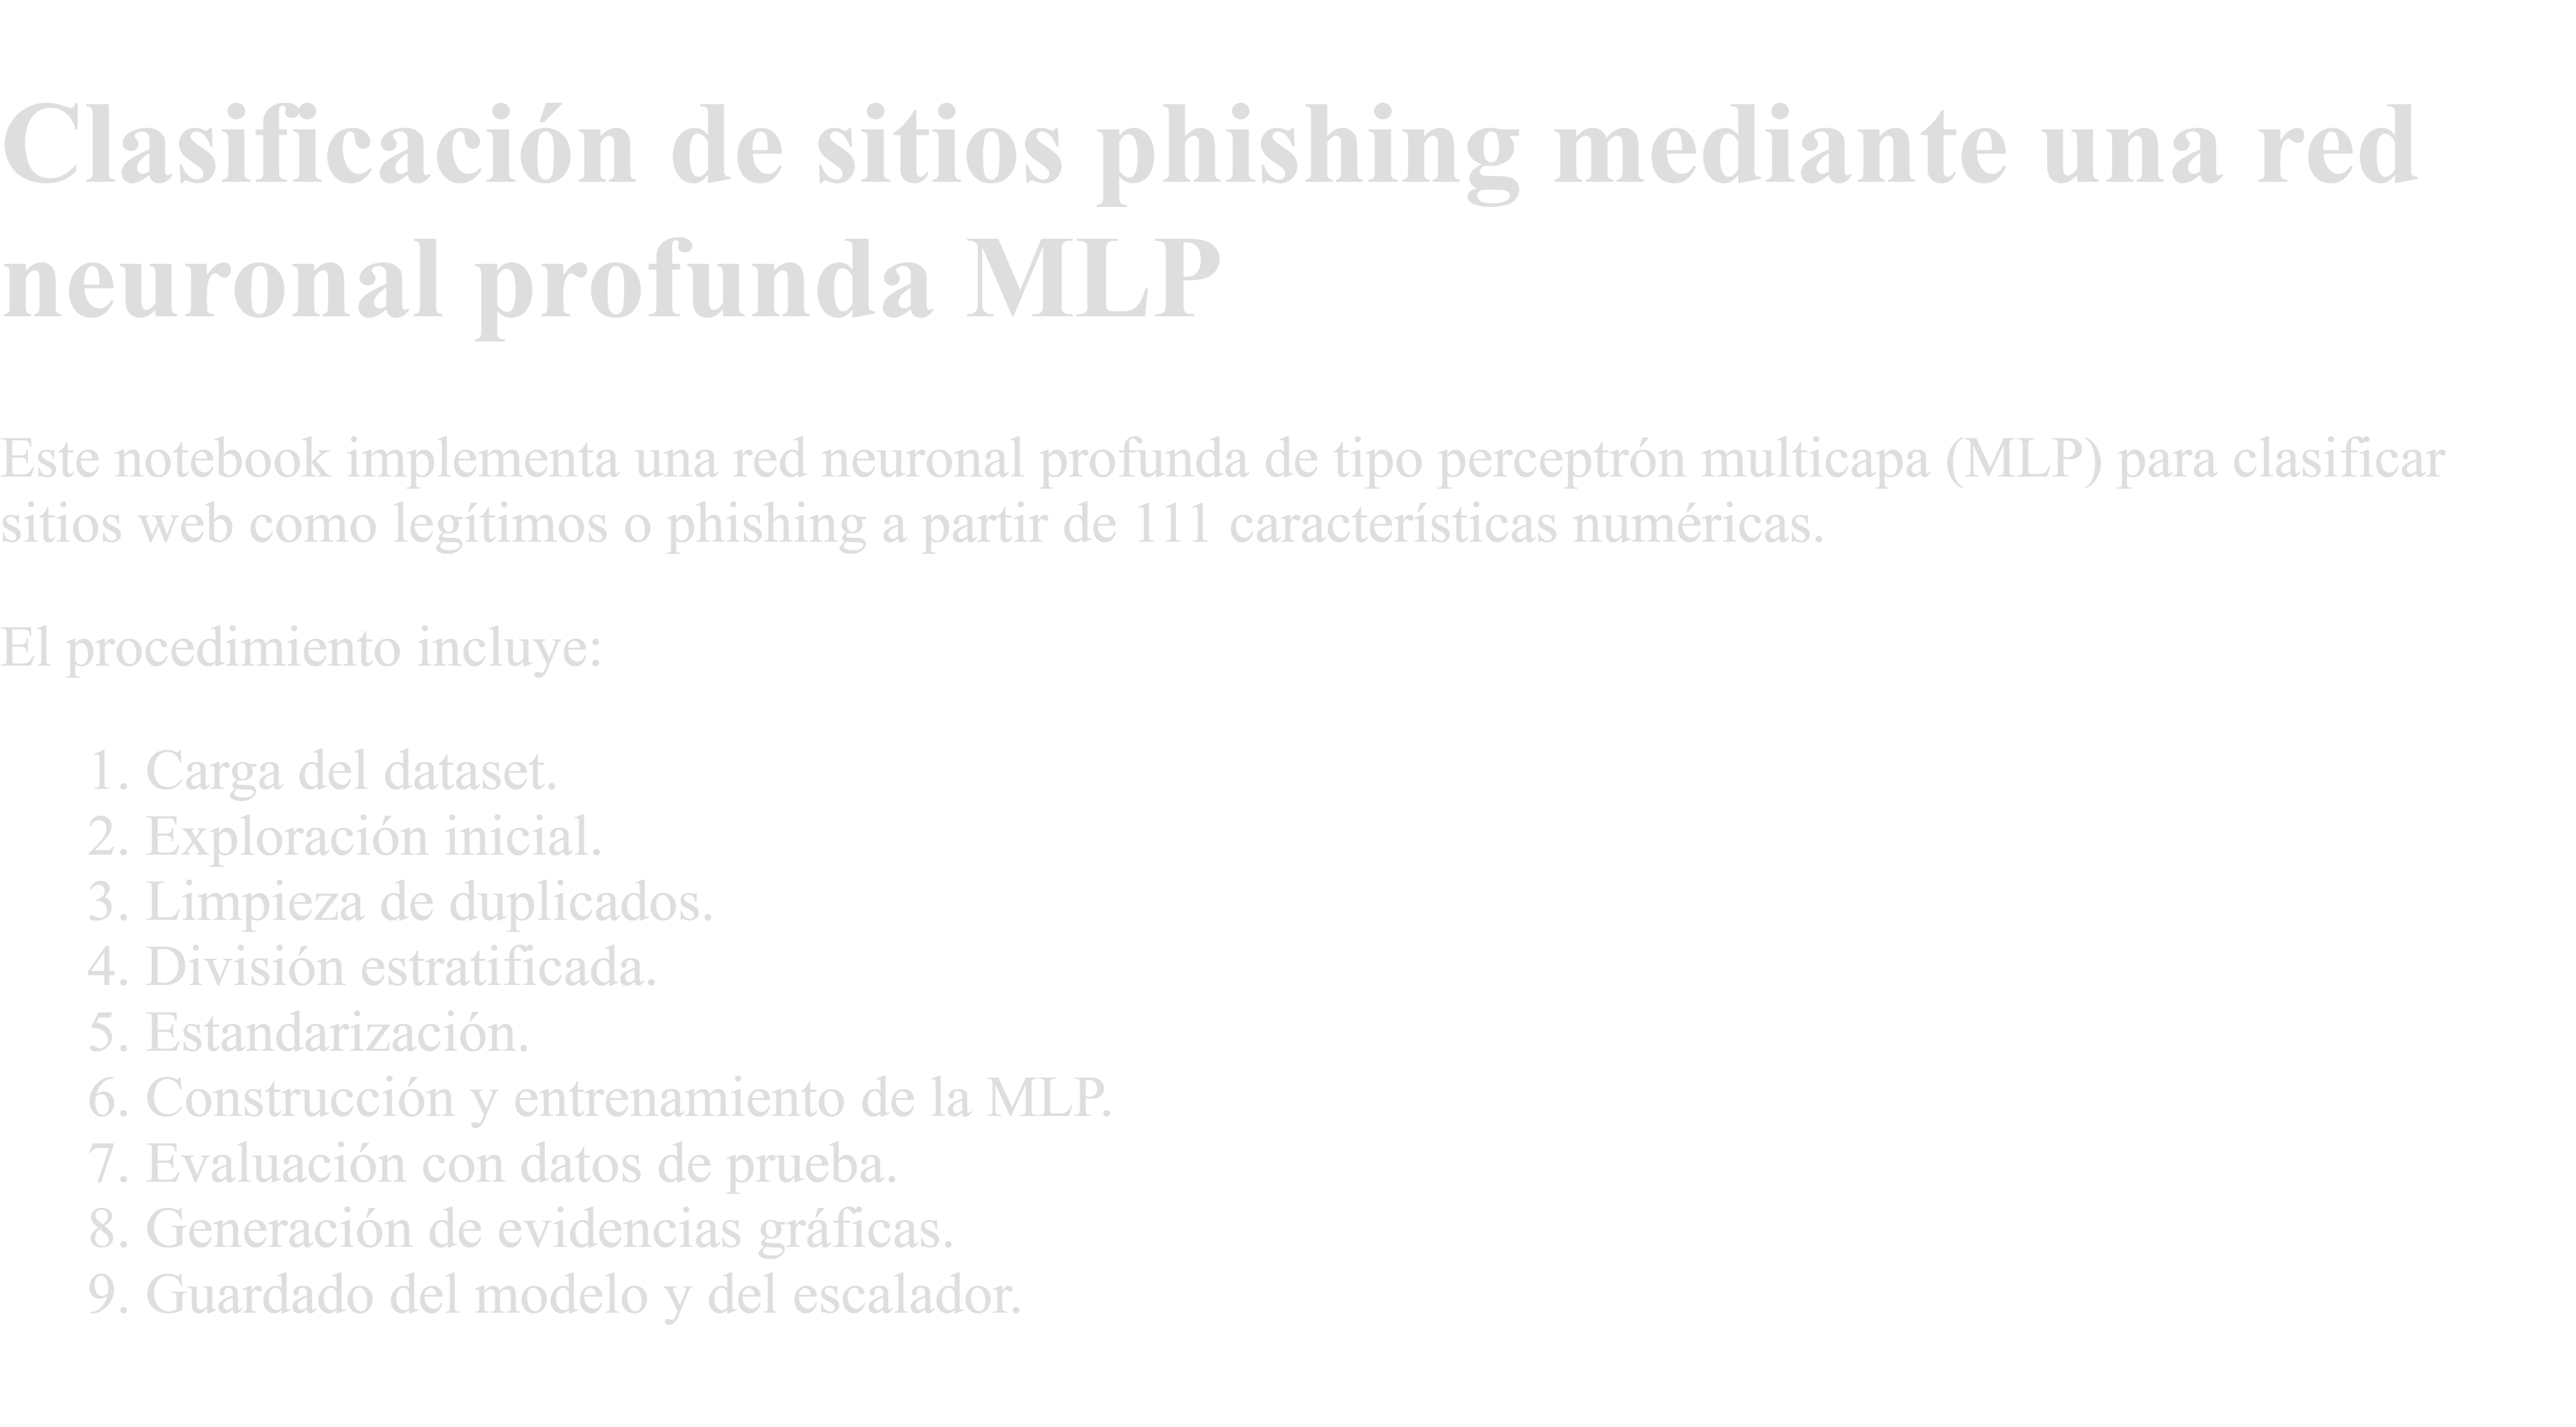

In [ ]:
import os
import random
import joblib
import urllib.request
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
    roc_curve,
    roc_auc_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)
from tensorflow.keras.metrics import Precision, Recall, AUC

# Semilla para reproducibilidad
SEMILLA = 42

random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)

print("TensorFlow:", tf.__version__)
print("Pandas:", pd.__version__)
print("Semilla configurada:", SEMILLA)

TensorFlow: 2.21.0
Pandas: 2.2.3
Semilla configurada: 42


In [ ]:
import pandas as pd

URL_DATASET = "https://raw.githubusercontent.com/FabianAlbarracin/phishing-mlp/refs/heads/main/dataset_full.csv"

df_original = pd.read_csv(URL_DATASET)

print("Dataset cargado correctamente.")
print("Dimensiones:", df_original.shape)

Dataset cargado correctamente.
Dimensiones: (88647, 112)


## 1. Configuración de rutas

Se monta Google Drive y se definen las rutas del dataset y de los archivos de salida.

In [ ]:
# URL pública directa del dataset en GitHub
URL_DATASET = (
    "https://raw.githubusercontent.com/FabianAlbarracin/"
    "phishing-mlp/refs/heads/main/dataset_full.csv"
)

# Rutas temporales dentro de Google Colab
RUTA_DATASET = "/content/dataset_full.csv"
RUTA_RESULTADOS = "/content/resultados"

# Rutas de los archivos generados
RUTA_MODELO = os.path.join(
    RUTA_RESULTADOS,
    "modelo_phishing_mlp.keras"
)

RUTA_SCALER = os.path.join(
    RUTA_RESULTADOS,
    "scaler_phishing.pkl"
)

# Crear la carpeta de resultados
os.makedirs(RUTA_RESULTADOS, exist_ok=True)

# Descargar el dataset si aún no existe
if not os.path.exists(RUTA_DATASET):
    print("Descargando dataset público desde GitHub...")

    urllib.request.urlretrieve(
        URL_DATASET,
        RUTA_DATASET
    )

# Verificar que la descarga fue correcta
if not os.path.exists(RUTA_DATASET):
    raise FileNotFoundError(
        "No fue posible descargar el dataset."
    )

print("Dataset:", RUTA_DATASET)
print("Resultados:", RUTA_RESULTADOS)
print("Modelo:", RUTA_MODELO)
print("Escalador:", RUTA_SCALER)

Descargando dataset público desde GitHub...
Dataset: /content/dataset_full.csv
Resultados: /content/resultados
Modelo: /content/resultados/modelo_phishing_mlp.keras
Escalador: /content/resultados/scaler_phishing.pkl


## 2. Carga y exploración inicial del dataset

Se revisan las dimensiones, tipos de datos, valores nulos, valores infinitos, duplicados y distribución de la variable objetivo.

In [ ]:
df_original = pd.read_csv(RUTA_DATASET)

print("Dimensiones originales:", df_original.shape)
print("Número de variables predictoras:", df_original.shape[1] - 1)
print("Variable objetivo:", df_original.columns[-1])

total_nulos = int(df_original.isnull().sum().sum())

columnas_numericas = df_original.select_dtypes(
    include=np.number
)

total_infinitos = int(
    np.isinf(columnas_numericas).sum().sum()
)

total_duplicados = int(
    df_original.duplicated().sum()
)

print("\nValores nulos:", total_nulos)
print("Valores infinitos:", total_infinitos)
print("Filas duplicadas:", total_duplicados)

print("\nTipos de datos:")
print(df_original.dtypes.value_counts())

print("\nDistribución original:")
print(df_original["phishing"].value_counts())

print("\nDistribución porcentual original:")
print(
    df_original["phishing"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Dimensiones originales: (88647, 112)
Número de variables predictoras: 111
Variable objetivo: phishing

Valores nulos: 0
Valores infinitos: 0
Filas duplicadas: 1438

Tipos de datos:
int64      111
float64      1
Name: count, dtype: int64

Distribución original:
phishing
0    58000
1    30647
Name: count, dtype: int64

Distribución porcentual original:
phishing
0    65.43
1    34.57
Name: proportion, dtype: float64


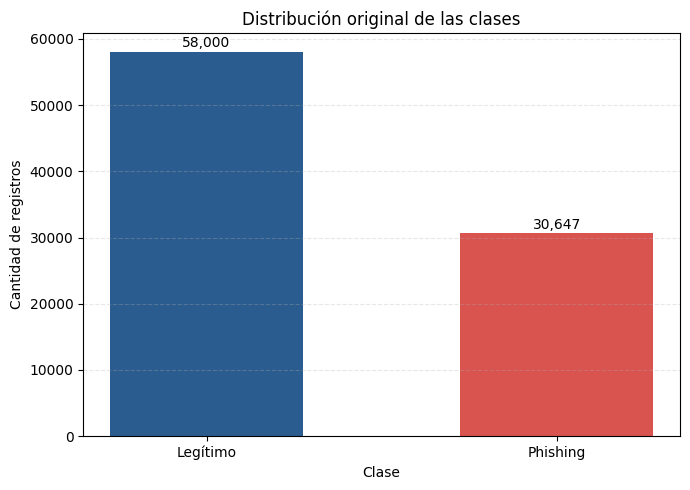

Gráfica guardada en:
/content/resultados/distribucion_clases_original.png


In [ ]:
conteo_original = (
    df_original["phishing"]
    .value_counts()
    .sort_index()
)

etiquetas = ["Legítimo", "Phishing"]

plt.figure(figsize=(7, 5))

barras = plt.bar(
    etiquetas,
    conteo_original.values,
    color=["#2b5c8f", "#d9534f"],
    width=0.55
)

plt.title("Distribución original de las clases")
plt.xlabel("Clase")
plt.ylabel("Cantidad de registros")
plt.grid(axis="y", linestyle="--", alpha=0.3)

for barra in barras:
    cantidad = int(barra.get_height())

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        cantidad + 700,
        f"{cantidad:,}",
        ha="center"
    )

plt.tight_layout()

ruta_distribucion_original = os.path.join(
    RUTA_RESULTADOS,
    "distribucion_clases_original.png"
)

plt.savefig(
    ruta_distribucion_original,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada en:")
print(ruta_distribucion_original)

## 3. Limpieza del dataset

Se eliminan valores inválidos y registros duplicados. La eliminación de duplicados reduce el riesgo de que una misma observación aparezca simultáneamente en entrenamiento y prueba.

In [ ]:
df = (
    df_original
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .drop_duplicates()
    .reset_index(drop=True)
)

duplicados_eliminados = len(df_original) - len(df)

print("Dimensiones originales:", df_original.shape)
print("Dimensiones después de la limpieza:", df.shape)
print("Registros eliminados:", duplicados_eliminados)

print("\nDistribución final:")
print(df["phishing"].value_counts())

print("\nDistribución porcentual final:")
print(
    df["phishing"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nClases encontradas:")
print(sorted(df["phishing"].unique()))

assert df.shape == (87209, 112)
assert df.isnull().sum().sum() == 0
assert df.duplicated().sum() == 0
assert set(df["phishing"].unique()) == {0, 1}

print("\nValidaciones completadas correctamente.")

Dimensiones originales: (88647, 112)
Dimensiones después de la limpieza: (87209, 112)
Registros eliminados: 1438

Distribución final:
phishing
0    56712
1    30497
Name: count, dtype: int64

Distribución porcentual final:
phishing
0    65.03
1    34.97
Name: proportion, dtype: float64

Clases encontradas:
[np.int64(0), np.int64(1)]

Validaciones completadas correctamente.


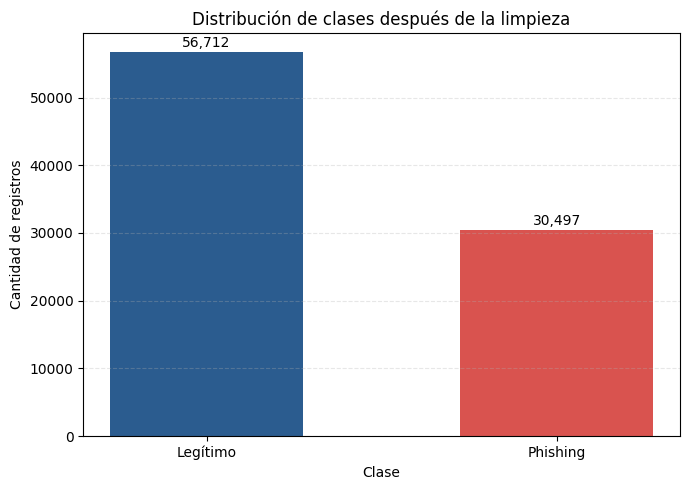

Gráfica guardada en:
/content/resultados/distribucion_clases_limpia.png


In [ ]:
conteo_limpio = (
    df["phishing"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 5))

barras = plt.bar(
    etiquetas,
    conteo_limpio.values,
    color=["#2b5c8f", "#d9534f"],
    width=0.55
)

plt.title("Distribución de clases después de la limpieza")
plt.xlabel("Clase")
plt.ylabel("Cantidad de registros")
plt.grid(axis="y", linestyle="--", alpha=0.3)

for barra in barras:
    cantidad = int(barra.get_height())

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        cantidad + 700,
        f"{cantidad:,}",
        ha="center"
    )

plt.tight_layout()

ruta_distribucion_limpia = os.path.join(
    RUTA_RESULTADOS,
    "distribucion_clases_limpia.png"
)

plt.savefig(
    ruta_distribucion_limpia,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada en:")
print(ruta_distribucion_limpia)

## 4. División y estandarización

El dataset limpio se divide de forma estratificada en:

- 70 % para entrenamiento.
- 15 % para validación.
- 15 % para prueba.

El escalador se ajusta exclusivamente con el conjunto de entrenamiento para evitar fuga de información.

In [ ]:
X = df.drop(columns=["phishing"])
y = df["phishing"]

nombres_variables = X.columns.tolist()

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEMILLA,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEMILLA,
    stratify=y_temp
)

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

print("\nDistribución de entrenamiento:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDistribución de validación:")
print(
    y_val.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDistribución de prueba:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Entrenamiento: (61046, 111)
Validación: (13081, 111)
Prueba: (13082, 111)

Distribución de entrenamiento:
phishing
0    65.03
1    34.97
Name: proportion, dtype: float64

Distribución de validación:
phishing
0    65.03
1    34.97
Name: proportion, dtype: float64

Distribución de prueba:
phishing
0    65.03
1    34.97
Name: proportion, dtype: float64


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Entrenamiento estandarizado:", X_train_scaled.shape)
print("Validación estandarizada:", X_val_scaled.shape)
print("Prueba estandarizada:", X_test_scaled.shape)

print(
    "\nMedia aproximada del entrenamiento:",
    round(float(X_train_scaled.mean()), 6)
)

print(
    "Desviación aproximada del entrenamiento:",
    round(float(X_train_scaled.std()), 6)
)

Entrenamiento estandarizado: (61046, 111)
Validación estandarizada: (13081, 111)
Prueba estandarizada: (13082, 111)

Media aproximada del entrenamiento: 0.0
Desviación aproximada del entrenamiento: 0.939618


In [ ]:
import time
import gc

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

In [ ]:
CONFIGURACIONES = {
    "MLP_A_compacta": {
        "capas": [64, 32],
        "dropout": [0.20, 0.10],
        "learning_rate": 0.001
    },

    "MLP_B_referencia": {
        "capas": [128, 64],
        "dropout": [0.30, 0.20],
        "learning_rate": 0.001
    },

    "MLP_C_amplia": {
        "capas": [256, 128],
        "dropout": [0.40, 0.30],
        "learning_rate": 0.0005
    }
}

for nombre, configuracion in CONFIGURACIONES.items():
    print(nombre, configuracion)

MLP_A_compacta {'capas': [64, 32], 'dropout': [0.2, 0.1], 'learning_rate': 0.001}
MLP_B_referencia {'capas': [128, 64], 'dropout': [0.3, 0.2], 'learning_rate': 0.001}
MLP_C_amplia {'capas': [256, 128], 'dropout': [0.4, 0.3], 'learning_rate': 0.0005}


In [ ]:
def construir_modelo_mlp(nombre, configuracion, numero_entradas):
    # Limpiar modelos anteriores y mantener reproducibilidad
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    modelo = Sequential(name=nombre)

    # Capa de entrada
    modelo.add(
        Input(
            shape=(numero_entradas,),
            name="entrada"
        )
    )

    # Capas ocultas definidas por cada configuración
    for indice, neuronas in enumerate(configuracion["capas"]):
        modelo.add(
            Dense(
                neuronas,
                activation="relu",
                name=f"dense_{indice + 1}"
            )
        )

        modelo.add(
            Dropout(
                configuracion["dropout"][indice],
                name=f"dropout_{indice + 1}"
            )
        )

    # Clasificación binaria
    modelo.add(
        Dense(
            1,
            activation="sigmoid",
            name="salida_phishing"
        )
    )

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=configuracion["learning_rate"]
        ),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )

    return modelo

In [ ]:
modelo_prueba = construir_modelo_mlp(
    nombre="MLP_A_prueba",
    configuracion=CONFIGURACIONES["MLP_A_compacta"],
    numero_entradas=X_train_scaled.shape[1]
)

modelo_prueba.summary()

Model: "MLP_A_prueba"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         7,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_phishing (Dense)         │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,281 (36.25 KB)

 Trainable params: 9,281 (36.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def entrenar_y_evaluar(
    nombre,
    configuracion,
    X_train,
    y_train,
    X_val,
    y_val
):
    modelo = construir_modelo_mlp(
        nombre=nombre,
        configuracion=configuracion,
        numero_entradas=X_train.shape[1]
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=0
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=0
    )

    inicio = time.perf_counter()

    historial = modelo.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=30,
        batch_size=256,
        callbacks=[early_stopping, reduce_lr],
        verbose=0
    )

    tiempo = time.perf_counter() - inicio

    probabilidades = modelo.predict(
        X_val,
        verbose=0
    ).ravel()

    predicciones = (
        probabilidades >= 0.5
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predicciones
    ).ravel()

    resultado = {
        "modelo": nombre,
        "capas": str(configuracion["capas"]),
        "parametros": modelo.count_params(),
        "epocas": len(historial.history["loss"]),
        "tiempo_segundos": tiempo,
        "accuracy": accuracy_score(y_val, predicciones),
        "precision": precision_score(
            y_val, predicciones, zero_division=0
        ),
        "recall": recall_score(
            y_val, predicciones, zero_division=0
        ),
        "f1": f1_score(
            y_val, predicciones, zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_val, probabilidades
        ),
        "falsos_positivos": int(fp),
        "falsos_negativos": int(fn)
    }

    return modelo, historial, resultado

In [ ]:
modelo_A, historial_A, resultado_A = entrenar_y_evaluar(
    nombre="MLP_A_compacta",
    configuracion=CONFIGURACIONES["MLP_A_compacta"],
    X_train=X_train_scaled,
    y_train=y_train,
    X_val=X_val_scaled,
    y_val=y_val
)

print("Entrenamiento de MLP A completado\n")

for metrica, valor in resultado_A.items():
    if isinstance(valor, float):
        print(f"{metrica}: {valor:.4f}")
    else:
        print(f"{metrica}: {valor}")

Entrenamiento de MLP A completado

modelo: MLP_A_compacta
capas: [64, 32]
parametros: 9281
epocas: 30
tiempo_segundos: 39.5749
accuracy: 0.9589
precision: 0.9437
recall: 0.9386
f1: 0.9411
roc_auc: 0.9921
falsos_positivos: 256
falsos_negativos: 281


In [ ]:
modelo_B, historial_B, resultado_B = entrenar_y_evaluar(
    nombre="MLP_B_referencia",
    configuracion=CONFIGURACIONES["MLP_B_referencia"],
    X_train=X_train_scaled,
    y_train=y_train,
    X_val=X_val_scaled,
    y_val=y_val
)

print("Entrenamiento de MLP B completado\n")

for metrica, valor in resultado_B.items():
    if isinstance(valor, float):
        print(f"{metrica}: {valor:.4f}")
    else:
        print(f"{metrica}: {valor}")

Entrenamiento de MLP B completado

modelo: MLP_B_referencia
capas: [128, 64]
parametros: 22657
epocas: 30
tiempo_segundos: 45.3988
accuracy: 0.9606
precision: 0.9479
recall: 0.9390
f1: 0.9434
roc_auc: 0.9924
falsos_positivos: 236
falsos_negativos: 279


In [ ]:
modelo_C, historial_C, resultado_C = entrenar_y_evaluar(
    nombre="MLP_C_amplia",
    configuracion=CONFIGURACIONES["MLP_C_amplia"],
    X_train=X_train_scaled,
    y_train=y_train,
    X_val=X_val_scaled,
    y_val=y_val
)

print("Entrenamiento de MLP C completado\n")

for metrica, valor in resultado_C.items():
    if isinstance(valor, float):
        print(f"{metrica}: {valor:.4f}")
    else:
        print(f"{metrica}: {valor}")

Entrenamiento de MLP C completado

modelo: MLP_C_amplia
capas: [256, 128]
parametros: 61697
epocas: 30
tiempo_segundos: 74.9924
accuracy: 0.9602
precision: 0.9482
recall: 0.9373
f1: 0.9427
roc_auc: 0.9925
falsos_positivos: 234
falsos_negativos: 287


In [ ]:
resultados_modelos = [
    resultado_A,
    resultado_B,
    resultado_C
]

df_comparacion = pd.DataFrame(resultados_modelos)

columnas = [
    "modelo",
    "capas",
    "parametros",
    "epocas",
    "tiempo_segundos",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "falsos_positivos",
    "falsos_negativos"
]

df_comparacion = df_comparacion[columnas]

display(df_comparacion.round(4))

,modelo,capas,parametros,epocas,tiempo_segundos,accuracy,precision,recall,f1,roc_auc,falsos_positivos,falsos_negativos
0,MLP_A_compacta,"[64, 32]",9281,30,39.5749,0.9589,0.9437,0.9386,0.9411,0.9921,256,281
1,MLP_B_referencia,"[128, 64]",22657,30,45.3988,0.9606,0.9479,0.9390,0.9434,0.9924,236,279
2,MLP_C_amplia,"[256, 128]",61697,30,74.9924,0.9602,0.9482,0.9373,0.9427,0.9925,234,287


In [ ]:
# Probabilidades generadas por la MLP B sobre validación
probabilidades_B = modelo_B.predict(
    X_val_scaled,
    verbose=0
).ravel()

resultados_umbrales = []

for umbral in [0.40, 0.50, 0.60]:
    predicciones = (
        probabilidades_B >= umbral
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predicciones
    ).ravel()

    resultados_umbrales.append({
        "umbral": umbral,
        "accuracy": accuracy_score(y_val, predicciones),
        "precision": precision_score(
            y_val, predicciones, zero_division=0
        ),
        "recall": recall_score(
            y_val, predicciones, zero_division=0
        ),
        "f1": f1_score(
            y_val, predicciones, zero_division=0
        ),
        "falsos_positivos": int(fp),
        "falsos_negativos": int(fn)
    })

df_umbrales = pd.DataFrame(resultados_umbrales)

display(df_umbrales.round(4))

,umbral,accuracy,precision,recall,f1,falsos_positivos,falsos_negativos
0,0.4,0.9602,0.9329,0.9550,0.9438,314,206
1,0.5,0.9606,0.9479,0.9390,0.9434,236,279
2,0.6,0.9593,0.9585,0.9237,0.9408,183,349


In [ ]:
# Evaluación final del modelo seleccionado sobre el conjunto de prueba
probabilidades_test_B = modelo_B.predict(
    X_test_scaled,
    verbose=0
).ravel()

UMBRAL_FINAL = 0.40

predicciones_test_B = (
    probabilidades_test_B >= UMBRAL_FINAL
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    predicciones_test_B
).ravel()

resultado_final = {
    "modelo_seleccionado": "MLP_B_referencia",
    "umbral": UMBRAL_FINAL,
    "accuracy": accuracy_score(y_test, predicciones_test_B),
    "precision": precision_score(
        y_test, predicciones_test_B, zero_division=0
    ),
    "recall": recall_score(
        y_test, predicciones_test_B, zero_division=0
    ),
    "f1": f1_score(
        y_test, predicciones_test_B, zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test, probabilidades_test_B
    ),
    "verdaderos_negativos": int(tn),
    "falsos_positivos": int(fp),
    "falsos_negativos": int(fn),
    "verdaderos_positivos": int(tp)
}

print("EVALUACIÓN FINAL EN PRUEBA\n")

for metrica, valor in resultado_final.items():
    if isinstance(valor, float):
        print(f"{metrica}: {valor:.4f}")
    else:
        print(f"{metrica}: {valor}")

EVALUACIÓN FINAL EN PRUEBA

modelo_seleccionado: MLP_B_referencia
umbral: 0.4000
accuracy: 0.9609
precision: 0.9393
recall: 0.9497
f1: 0.9445
roc_auc: 0.9925
verdaderos_negativos: 8226
falsos_positivos: 281
falsos_negativos: 230
verdaderos_positivos: 4345


In [ ]:
# Guardar evidencias de la comparación experimental
RUTA_COMPARACION = os.path.join(
    RUTA_RESULTADOS,
    "comparacion_modelos_mlp.csv"
)

RUTA_UMBRALES = os.path.join(
    RUTA_RESULTADOS,
    "comparacion_umbrales.csv"
)

RUTA_RESULTADO_FINAL = os.path.join(
    RUTA_RESULTADOS,
    "resultado_final_unidad2.txt"
)

df_comparacion.to_csv(
    RUTA_COMPARACION,
    index=False
)

df_umbrales.to_csv(
    RUTA_UMBRALES,
    index=False
)

with open(RUTA_RESULTADO_FINAL, "w", encoding="utf-8") as archivo:
    archivo.write("RESULTADO FINAL - UNIDAD 2\n")
    archivo.write("=" * 45 + "\n")

    for metrica, valor in resultado_final.items():
        if isinstance(valor, float):
            archivo.write(f"{metrica}: {valor:.4f}\n")
        else:
            archivo.write(f"{metrica}: {valor}\n")

print("Evidencias guardadas:")
print(RUTA_COMPARACION)
print(RUTA_UMBRALES)
print(RUTA_RESULTADO_FINAL)

Evidencias guardadas:
/content/resultados/comparacion_modelos_mlp.csv
/content/resultados/comparacion_umbrales.csv
/content/resultados/resultado_final_unidad2.txt


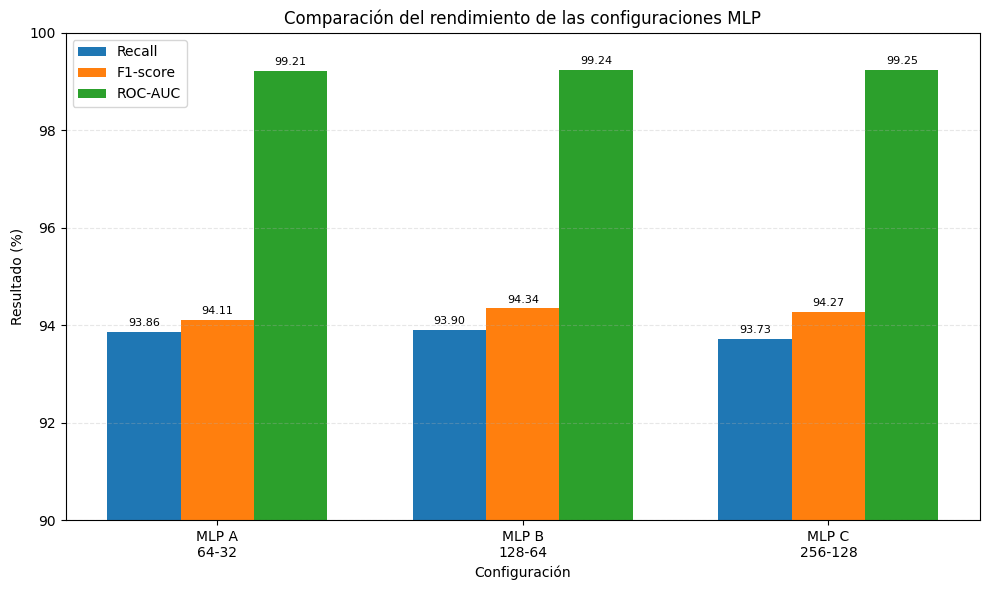

Gráfica guardada en:
/content/resultados/comparacion_rendimiento_modelos.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os

modelos = [
    "MLP A\n64-32",
    "MLP B\n128-64",
    "MLP C\n256-128"
]

recall = df_comparacion["recall"].to_numpy() * 100
f1 = df_comparacion["f1"].to_numpy() * 100
roc_auc = df_comparacion["roc_auc"].to_numpy() * 100

x = np.arange(len(modelos))
ancho = 0.24

fig, ax = plt.subplots(figsize=(10, 6))

barras_recall = ax.bar(
    x - ancho,
    recall,
    ancho,
    label="Recall"
)

barras_f1 = ax.bar(
    x,
    f1,
    ancho,
    label="F1-score"
)

barras_auc = ax.bar(
    x + ancho,
    roc_auc,
    ancho,
    label="ROC-AUC"
)

ax.set_title("Comparación del rendimiento de las configuraciones MLP")
ax.set_xlabel("Configuración")
ax.set_ylabel("Resultado (%)")
ax.set_xticks(x)
ax.set_xticklabels(modelos)
ax.set_ylim(90, 100)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

for grupo in [barras_recall, barras_f1, barras_auc]:
    for barra in grupo:
        valor = barra.get_height()

        ax.text(
            barra.get_x() + barra.get_width() / 2,
            valor + 0.08,
            f"{valor:.2f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

plt.tight_layout()

RUTA_GRAFICA_MODELOS = os.path.join(
    RUTA_RESULTADOS,
    "comparacion_rendimiento_modelos.png"
)

plt.savefig(
    RUTA_GRAFICA_MODELOS,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada en:")
print(RUTA_GRAFICA_MODELOS)

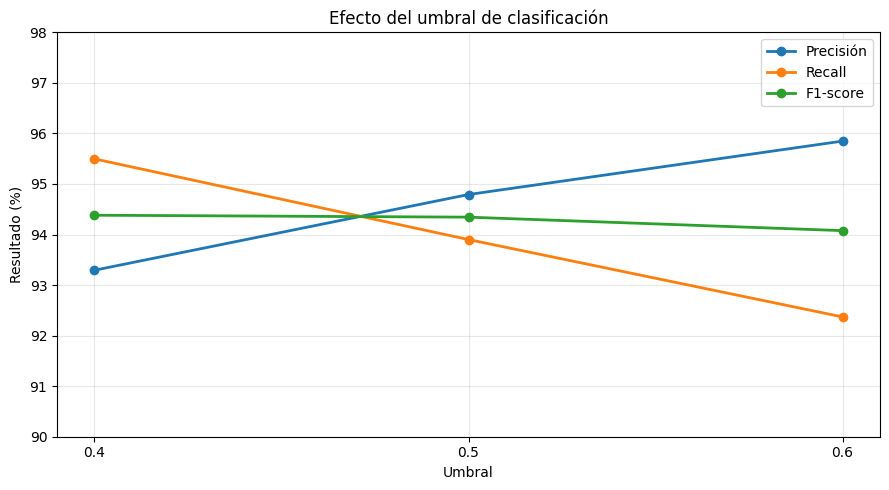

Gráfica guardada en:
/content/resultados/comparacion_umbrales.png


In [ ]:
umbrales = df_umbrales["umbral"].astype(str)

plt.figure(figsize=(9, 5))

plt.plot(
    umbrales,
    df_umbrales["precision"] * 100,
    marker="o",
    linewidth=2,
    label="Precisión"
)

plt.plot(
    umbrales,
    df_umbrales["recall"] * 100,
    marker="o",
    linewidth=2,
    label="Recall"
)

plt.plot(
    umbrales,
    df_umbrales["f1"] * 100,
    marker="o",
    linewidth=2,
    label="F1-score"
)

plt.title("Efecto del umbral de clasificación")
plt.xlabel("Umbral")
plt.ylabel("Resultado (%)")
plt.ylim(90, 98)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

RUTA_GRAFICA_UMBRALES = os.path.join(
    RUTA_RESULTADOS,
    "comparacion_umbrales.png"
)

plt.savefig(
    RUTA_GRAFICA_UMBRALES,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada en:")
print(RUTA_GRAFICA_UMBRALES)

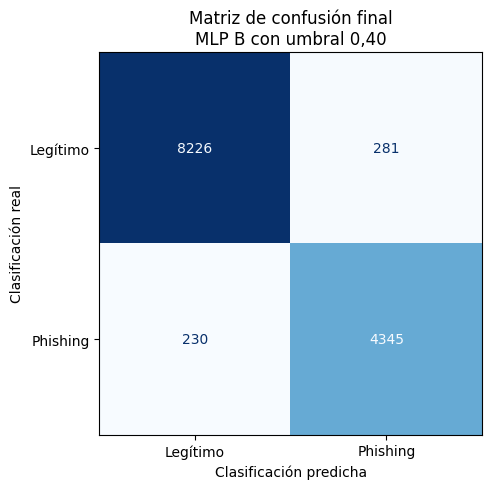

Matriz guardada en:
/content/resultados/matriz_confusion_final_unidad2.png


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import os

matriz_final = confusion_matrix(
    y_test,
    predicciones_test_B
)

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_final,
    display_labels=["Legítimo", "Phishing"]
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

ax.set_title("Matriz de confusión final\nMLP B con umbral 0,40")
ax.set_xlabel("Clasificación predicha")
ax.set_ylabel("Clasificación real")

plt.tight_layout()

RUTA_MATRIZ_FINAL = os.path.join(
    RUTA_RESULTADOS,
    "matriz_confusion_final_unidad2.png"
)

plt.savefig(
    RUTA_MATRIZ_FINAL,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Matriz guardada en:")
print(RUTA_MATRIZ_FINAL)

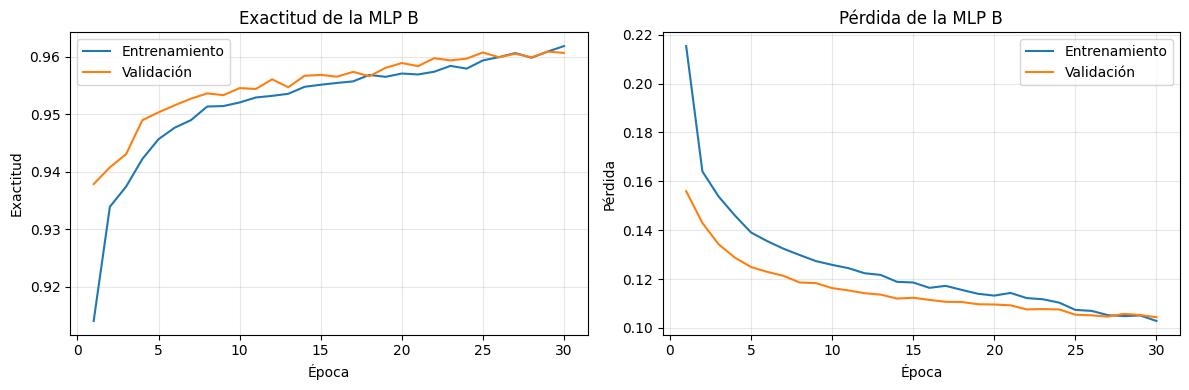

Curvas guardadas en:
/content/resultados/curvas_entrenamiento_mlp_b.png


In [ ]:
epocas = range(
    1,
    len(historial_B.history["loss"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Exactitud
axes[0].plot(
    epocas,
    historial_B.history["accuracy"],
    label="Entrenamiento"
)

axes[0].plot(
    epocas,
    historial_B.history["val_accuracy"],
    label="Validación"
)

axes[0].set_title("Exactitud de la MLP B")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Exactitud")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Pérdida
axes[1].plot(
    epocas,
    historial_B.history["loss"],
    label="Entrenamiento"
)

axes[1].plot(
    epocas,
    historial_B.history["val_loss"],
    label="Validación"
)

axes[1].set_title("Pérdida de la MLP B")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Pérdida")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

RUTA_CURVAS_B = os.path.join(
    RUTA_RESULTADOS,
    "curvas_entrenamiento_mlp_b.png"
)

plt.savefig(
    RUTA_CURVAS_B,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Curvas guardadas en:")
print(RUTA_CURVAS_B)

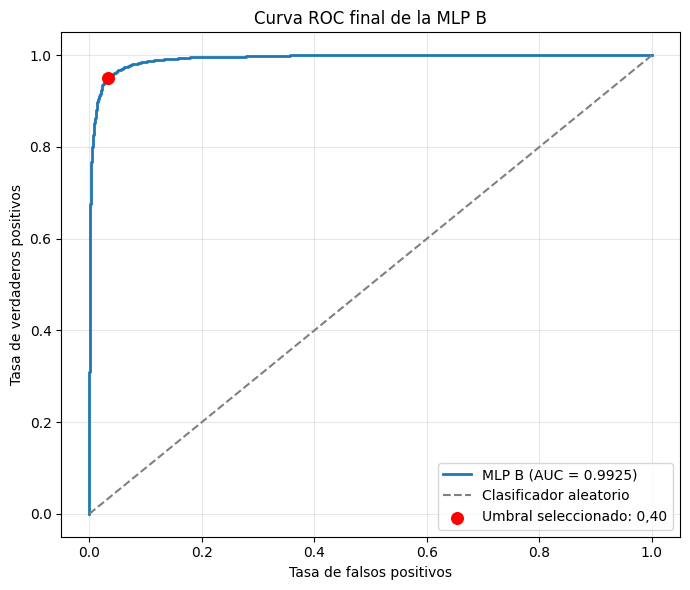

ROC-AUC final: 0.9925
Curva guardada en:
/content/resultados/curva_roc_final_mlp_b.png


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import os

# Calcular la curva ROC con las probabilidades del conjunto de prueba
fpr, tpr, umbrales_roc = roc_curve(
    y_test,
    probabilidades_test_B
)

auc_final = roc_auc_score(
    y_test,
    probabilidades_test_B
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"MLP B (AUC = {auc_final:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificador aleatorio"
)

# Marcar el punto correspondiente al umbral operativo 0,40
indice_umbral = np.argmin(
    np.abs(umbrales_roc - UMBRAL_FINAL)
)

plt.scatter(
    fpr[indice_umbral],
    tpr[indice_umbral],
    color="red",
    s=70,
    zorder=5,
    label="Umbral seleccionado: 0,40"
)

plt.title("Curva ROC final de la MLP B")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

RUTA_ROC_FINAL = os.path.join(
    RUTA_RESULTADOS,
    "curva_roc_final_mlp_b.png"
)

plt.savefig(
    RUTA_ROC_FINAL,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC-AUC final:", round(auc_final, 4))
print("Curva guardada en:")
print(RUTA_ROC_FINAL)

In [ ]:
import json
import joblib
import os

# Rutas de los archivos finales
RUTA_MODELO_FINAL = os.path.join(
    RUTA_RESULTADOS,
    "modelo_mlp_b_unidad2.keras"
)

RUTA_SCALER_FINAL = os.path.join(
    RUTA_RESULTADOS,
    "scaler_unidad2.pkl"
)

RUTA_CONFIGURACION = os.path.join(
    RUTA_RESULTADOS,
    "configuracion_modelo_final.json"
)

# Guardar modelo y escalador
modelo_B.save(RUTA_MODELO_FINAL)
joblib.dump(scaler, RUTA_SCALER_FINAL)

# Guardar configuración y métricas finales
configuracion_final = {
    "modelo": "MLP_B_referencia",
    "capas_ocultas": [128, 64],
    "dropout": [0.30, 0.20],
    "learning_rate_inicial": 0.001,
    "batch_size": 256,
    "epocas_maximas": 30,
    "parametros_entrenables": 22657,
    "umbral_operativo": 0.40,
    "accuracy_prueba": resultado_final["accuracy"],
    "precision_prueba": resultado_final["precision"],
    "recall_prueba": resultado_final["recall"],
    "f1_prueba": resultado_final["f1"],
    "roc_auc_prueba": resultado_final["roc_auc"],
    "falsos_positivos": resultado_final["falsos_positivos"],
    "falsos_negativos": resultado_final["falsos_negativos"]
}

with open(
    RUTA_CONFIGURACION,
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        configuracion_final,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("Modelo guardado en:")
print(RUTA_MODELO_FINAL)

print("\nEscalador guardado en:")
print(RUTA_SCALER_FINAL)

print("\nConfiguración guardada en:")
print(RUTA_CONFIGURACION)

Modelo guardado en:
/content/resultados/modelo_mlp_b_unidad2.keras

Escalador guardado en:
/content/resultados/scaler_unidad2.pkl

Configuración guardada en:
/content/resultados/configuracion_modelo_final.json


In [ ]:
archivos_unidad2 = [
    "comparacion_modelos_mlp.csv",
    "comparacion_umbrales.csv",
    "resultado_final_unidad2.txt",
    "comparacion_rendimiento_modelos.png",
    "comparacion_umbrales.png",
    "matriz_confusion_final_unidad2.png",
    "curvas_entrenamiento_mlp_b.png",
    "curva_roc_final_mlp_b.png",
    "modelo_mlp_b_unidad2.keras",
    "scaler_unidad2.pkl",
    "configuracion_modelo_final.json"
]

print("COMPROBACIÓN DE EVIDENCIAS\n")

todo_correcto = True

for nombre in archivos_unidad2:
    ruta = os.path.join(RUTA_RESULTADOS, nombre)
    existe = os.path.exists(ruta)

    print(
        f"[{'OK' if existe else 'FALTA'}] {nombre}"
    )

    if not existe:
        todo_correcto = False

if todo_correcto:
    print(
        "\nTodas las evidencias de la Unidad 2 "
        "fueron generadas correctamente."
    )
else:
    print(
        "\nFaltan evidencias. Revisa los elementos "
        "marcados como FALTA."
    )

COMPROBACIÓN DE EVIDENCIAS

[OK] comparacion_modelos_mlp.csv
[OK] comparacion_umbrales.csv
[OK] resultado_final_unidad2.txt
[OK] comparacion_rendimiento_modelos.png
[OK] comparacion_umbrales.png
[OK] matriz_confusion_final_unidad2.png
[OK] curvas_entrenamiento_mlp_b.png
[OK] curva_roc_final_mlp_b.png
[OK] modelo_mlp_b_unidad2.keras
[OK] scaler_unidad2.pkl
[OK] configuracion_modelo_final.json

Todas las evidencias de la Unidad 2 fueron generadas correctamente.


In [ ]:
import shutil
from google.colab import files

RUTA_ZIP = "/content/evidencias_unidad2_phishing"

shutil.make_archive(
    RUTA_ZIP,
    "zip",
    RUTA_RESULTADOS
)

print("Archivo generado:")
print(RUTA_ZIP + ".zip")

files.download(
    RUTA_ZIP + ".zip"
)


Archivo generado:
/content/evidencias_unidad2_phishing.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

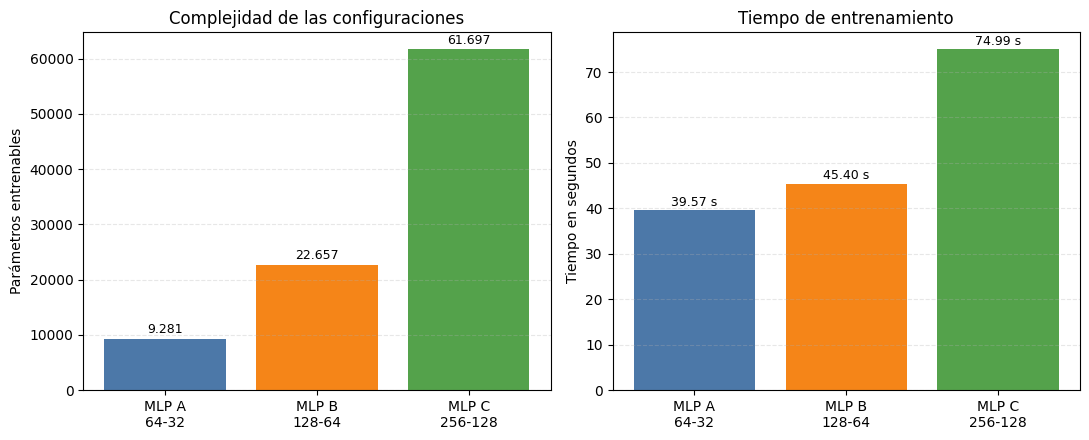

Gráfica guardada en:
/content/resultados/comparacion_complejidad_tiempo.png


In [ ]:
nombres = ["MLP A\n64-32", "MLP B\n128-64", "MLP C\n256-128"]

parametros = df_comparacion["parametros"].to_numpy()
tiempos = df_comparacion["tiempo_segundos"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Número de parámetros
barras_parametros = axes[0].bar(
    nombres,
    parametros,
    color=["#4C78A8", "#F58518", "#54A24B"]
)

axes[0].set_title("Complejidad de las configuraciones")
axes[0].set_ylabel("Parámetros entrenables")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

for barra, valor in zip(barras_parametros, parametros):
    axes[0].text(
        barra.get_x() + barra.get_width() / 2,
        valor + 1000,
        f"{valor:,}".replace(",", "."),
        ha="center",
        fontsize=9
    )

# Tiempo de entrenamiento
barras_tiempo = axes[1].bar(
    nombres,
    tiempos,
    color=["#4C78A8", "#F58518", "#54A24B"]
)

axes[1].set_title("Tiempo de entrenamiento")
axes[1].set_ylabel("Tiempo en segundos")
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

for barra, valor in zip(barras_tiempo, tiempos):
    axes[1].text(
        barra.get_x() + barra.get_width() / 2,
        valor + 1,
        f"{valor:.2f} s",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

RUTA_GRAFICA_EFICIENCIA = os.path.join(
    RUTA_RESULTADOS,
    "comparacion_complejidad_tiempo.png"
)

plt.savefig(
    RUTA_GRAFICA_EFICIENCIA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada en:")
print(RUTA_GRAFICA_EFICIENCIA)

## 5. Construcción de la red neuronal MLP

La arquitectura contiene dos capas ocultas con activación ReLU, regularización mediante Dropout y una salida Sigmoid para clasificación binaria.

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEMILLA)

model = Sequential([
    Input(
        shape=(X_train_scaled.shape[1],),
        name="entrada_caracteristicas"
    ),

    Dense(
        128,
        activation="relu",
        name="capa_densa_128"
    ),

    Dropout(
        0.30,
        name="dropout_30"
    ),

    Dense(
        64,
        activation="relu",
        name="capa_densa_64"
    ),

    Dropout(
        0.20,
        name="dropout_20"
    ),

    Dense(
        1,
        activation="sigmoid",
        name="salida_phishing"
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        Precision(name="precision"),
        Recall(name="recall"),
        AUC(name="auc")
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa_densa_128 (Dense)          │ (None, 128)            │        14,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_densa_64 (Dense)           │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_phishing (Dense)         │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,657 (88.50 KB)

 Trainable params: 22,657 (88.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

## 6. Entrenamiento

El modelo se entrena durante un máximo de 30 épocas, utilizando lotes de 256 observaciones y el subconjunto de validación para controlar el proceso.

In [ ]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(
        X_val_scaled,
        y_val
    ),
    epochs=30,
    batch_size=256,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

mejor_epoca = (
    int(np.argmin(history.history["val_loss"])) + 1
)

print("\nMejor época según val_loss:", mejor_epoca)
print(
    "Mejor pérdida de validación:",
    round(min(history.history["val_loss"]), 6)
)

Epoch 1/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9141 - auc: 0.9683 - loss: 0.2153 - precision: 0.8536 - recall: 0.9103 - val_accuracy: 0.9378 - val_auc: 0.9837 - val_loss: 0.1560 - val_precision: 0.8988 - val_recall: 0.9265 - learning_rate: 0.0010
Epoch 2/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9339 - auc: 0.9818 - loss: 0.1640 - precision: 0.8972 - recall: 0.9160 - val_accuracy: 0.9408 - val_auc: 0.9863 - val_loss: 0.1430 - val_precision: 0.9037 - val_recall: 0.9296 - learning_rate: 0.0010
Epoch 3/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9374 - auc: 0.9839 - loss: 0.1538 - precision: 0.9046 - recall: 0.9178 - val_accuracy: 0.9430 - val_auc: 0.9877 - val_loss: 0.1342 - val_precision: 0.9120 - val_recall: 0.9265 - learning_rate: 0.0010
Epoch 4/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9422 - auc: 0.9853 - loss: 0.1460 - precision: 0.9151 - recall: 0.9201 - val_accuracy: 0.9489 - val_auc: 0.9888 - val_loss: 0.1288 - va

## 7. Evaluación sobre el conjunto de prueba

El conjunto de prueba se utiliza después del entrenamiento para obtener una evaluación final sobre observaciones no utilizadas durante el ajuste de la red.

In [ ]:
resultados_test = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=1,
    return_dict=True
)

print("\nRESULTADOS FINALES EN PRUEBA")

for metrica, valor in resultados_test.items():
    print(f"{metrica}: {valor:.4f}")

409/409 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9619 - auc: 0.9924 - loss: 0.1041 - precision: 0.9539 - recall: 0.9364

RESULTADOS FINALES EN PRUEBA
accuracy: 0.9619
auc: 0.9924
loss: 0.1041
precision: 0.9539
recall: 0.9364


In [ ]:
y_prob = model.predict(
    X_test_scaled,
    verbose=0
).ravel()

UMBRAL = 0.5

y_pred = (
    y_prob >= UMBRAL
).astype(int)

f1_phishing = f1_score(
    y_test,
    y_pred,
    pos_label=1
)

matriz = confusion_matrix(
    y_test,
    y_pred
)

tn, fp, fn, tp = matriz.ravel()

print(f"F1-score para phishing: {f1_phishing:.4f}")

print("\nMatriz de confusión:")
print(matriz)

print("\nVerdaderos negativos:", tn)
print("Falsos positivos:", fp)
print("Falsos negativos:", fn)
print("Verdaderos positivos:", tp)

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Legítimo",
            "Phishing"
        ],
        digits=4
    )
)

F1-score para phishing: 0.9451

Matriz de confusión:
[[8300  207]
 [ 291 4284]]

Verdaderos negativos: 8300
Falsos positivos: 207
Falsos negativos: 291
Verdaderos positivos: 4284

Reporte de clasificación:
              precision    recall  f1-score   support

    Legítimo     0.9661    0.9757    0.9709      8507
    Phishing     0.9539    0.9364    0.9451      4575

    accuracy                         0.9619     13082
   macro avg     0.9600    0.9560    0.9580     13082
weighted avg     0.9619    0.9619    0.9618     13082



## 8. Evidencias gráficas

Se generan las curvas de entrenamiento, la matriz de confusión y la curva ROC.

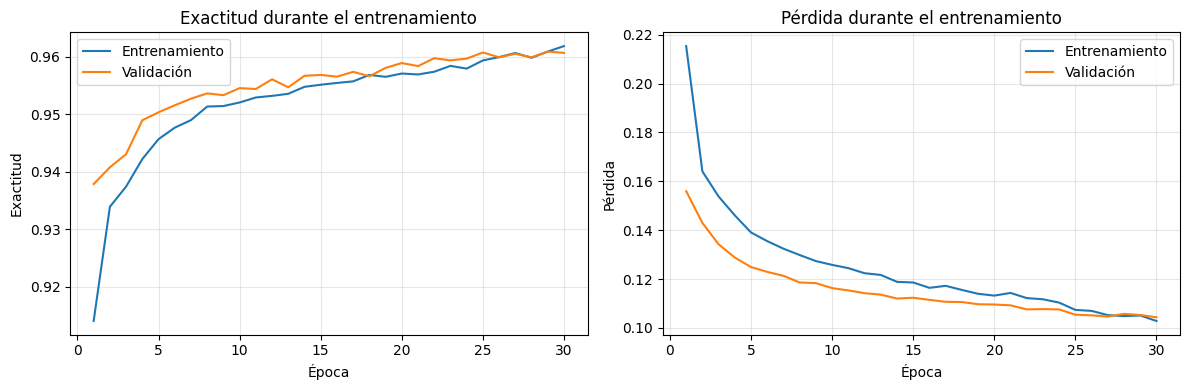

Gráfica guardada en:
/content/resultados/curvas_entrenamiento.png


In [ ]:
epocas = range(
    1,
    len(history.history["loss"]) + 1
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].plot(
    epocas,
    history.history["accuracy"],
    label="Entrenamiento"
)

axes[0].plot(
    epocas,
    history.history["val_accuracy"],
    label="Validación"
)

axes[0].set_title(
    "Exactitud durante el entrenamiento"
)

axes[0].set_xlabel("Época")
axes[0].set_ylabel("Exactitud")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epocas,
    history.history["loss"],
    label="Entrenamiento"
)

axes[1].plot(
    epocas,
    history.history["val_loss"],
    label="Validación"
)

axes[1].set_title(
    "Pérdida durante el entrenamiento"
)

axes[1].set_xlabel("Época")
axes[1].set_ylabel("Pérdida")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

ruta_curvas = os.path.join(
    RUTA_RESULTADOS,
    "curvas_entrenamiento.png"
)

plt.savefig(
    ruta_curvas,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada en:")
print(ruta_curvas)

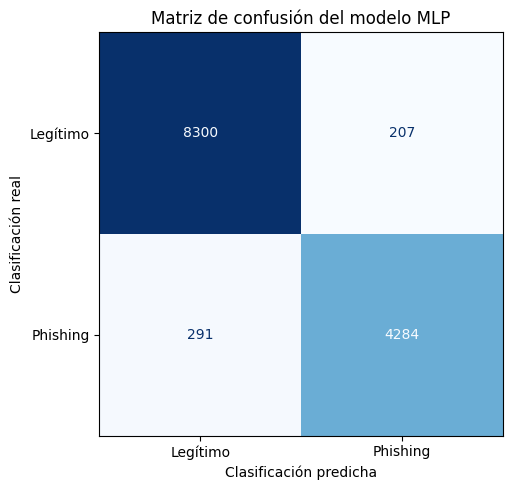

Matriz guardada en:
/content/resultados/matriz_confusion.png


In [ ]:
fig, ax = plt.subplots(
    figsize=(6, 5)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=[
        "Legítimo",
        "Phishing"
    ]
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

ax.set_title(
    "Matriz de confusión del modelo MLP"
)

ax.set_xlabel(
    "Clasificación predicha"
)

ax.set_ylabel(
    "Clasificación real"
)

plt.tight_layout()

ruta_matriz = os.path.join(
    RUTA_RESULTADOS,
    "matriz_confusion.png"
)

plt.savefig(
    ruta_matriz,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Matriz guardada en:")
print(ruta_matriz)

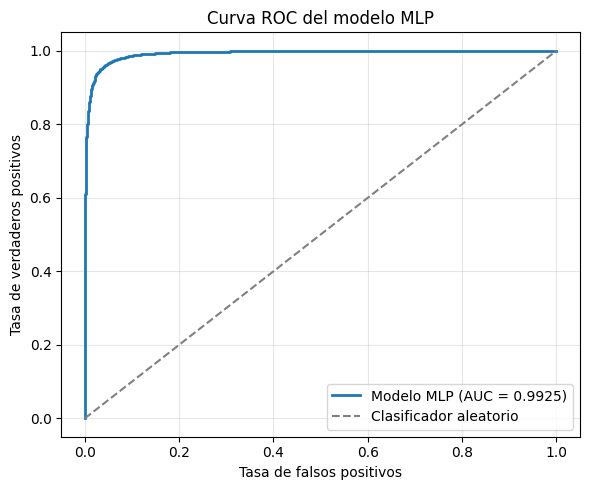

Curva ROC guardada en:
/content/resultados/curva_roc.png


In [ ]:
fpr, tpr, umbrales = roc_curve(
    y_test,
    y_prob
)

auc_roc = roc_auc_score(
    y_test,
    y_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Modelo MLP (AUC = {auc_roc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificador aleatorio"
)

plt.title("Curva ROC del modelo MLP")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

ruta_roc = os.path.join(
    RUTA_RESULTADOS,
    "curva_roc.png"
)

plt.savefig(
    ruta_roc,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Curva ROC guardada en:")
print(ruta_roc)

## 9. Guardado del modelo y del escalador

Se guardan la red neuronal entrenada y el escalador utilizado en la preparación de los datos. Ambos archivos son necesarios para reutilizar correctamente el prototipo.

In [ ]:
model.save(RUTA_MODELO)
joblib.dump(scaler, RUTA_SCALER)

ruta_variables = os.path.join(
    RUTA_RESULTADOS,
    "variables_modelo.txt"
)

with open(
    ruta_variables,
    "w",
    encoding="utf-8"
) as archivo:

    for variable in nombres_variables:
        archivo.write(variable + "\n")

print("Modelo guardado en:")
print(RUTA_MODELO)

print("\nEscalador guardado en:")
print(RUTA_SCALER)

print("\nLista de variables guardada en:")
print(ruta_variables)

Modelo guardado en:
/content/resultados/modelo_phishing_mlp.keras

Escalador guardado en:
/content/resultados/scaler_phishing.pkl

Lista de variables guardada en:
/content/resultados/variables_modelo.txt


In [ ]:
ruta_resumen = os.path.join(
    RUTA_RESULTADOS,
    "resultados_finales.txt"
)

with open(
    ruta_resumen,
    "w",
    encoding="utf-8"
) as archivo:

    archivo.write(
        "RESULTADOS DEL MODELO MLP PARA PHISHING\n"
    )

    archivo.write("=" * 50 + "\n")

    archivo.write(
        f"Registros originales: {len(df_original)}\n"
    )

    archivo.write(
        f"Duplicados eliminados: {duplicados_eliminados}\n"
    )

    archivo.write(
        f"Registros finales: {len(df)}\n"
    )

    archivo.write(
        f"Registros de entrenamiento: {len(X_train)}\n"
    )

    archivo.write(
        f"Registros de validación: {len(X_val)}\n"
    )

    archivo.write(
        f"Registros de prueba: {len(X_test)}\n\n"
    )

    archivo.write(
        f"Accuracy: {resultados_test['accuracy']:.4f}\n"
    )

    archivo.write(
        f"Precision: {resultados_test['precision']:.4f}\n"
    )

    archivo.write(
        f"Recall: {resultados_test['recall']:.4f}\n"
    )

    archivo.write(
        f"F1-score: {f1_phishing:.4f}\n"
    )

    archivo.write(
        f"ROC-AUC: {auc_roc:.4f}\n"
    )

    archivo.write(
        f"Loss: {resultados_test['loss']:.4f}\n\n"
    )

    archivo.write(
        f"Verdaderos negativos: {tn}\n"
    )

    archivo.write(
        f"Falsos positivos: {fp}\n"
    )

    archivo.write(
        f"Falsos negativos: {fn}\n"
    )

    archivo.write(
        f"Verdaderos positivos: {tp}\n"
    )

print("Resumen guardado en:")
print(ruta_resumen)

Resumen guardado en:
/content/resultados/resultados_finales.txt


In [ ]:
archivos_esperados = [
    RUTA_MODELO,
    RUTA_SCALER,
    ruta_variables,
    ruta_resumen,
    ruta_distribucion_original,
    ruta_distribucion_limpia,
    ruta_curvas,
    ruta_matriz,
    ruta_roc
]

print("COMPROBACIÓN FINAL\n")

todo_correcto = True

for ruta in archivos_esperados:
    existe = os.path.exists(ruta)

    estado = "OK" if existe else "FALTA"

    print(f"[{estado}] {os.path.basename(ruta)}")

    if not existe:
        todo_correcto = False

if todo_correcto:
    print(
        "\nNotebook ejecutado correctamente. "
        "Todos los archivos fueron generados."
    )
else:
    print(
        "\nFaltan archivos. Revisa las celdas anteriores."
    )

COMPROBACIÓN FINAL

[OK] modelo_phishing_mlp.keras
[OK] scaler_phishing.pkl
[OK] variables_modelo.txt
[OK] resultados_finales.txt
[OK] distribucion_clases_original.png
[OK] distribucion_clases_limpia.png
[OK] curvas_entrenamiento.png
[OK] matriz_confusion.png
[OK] curva_roc.png

Notebook ejecutado correctamente. Todos los archivos fueron generados.


In [ ]:
print("Entrenamiento:", X_train_scaled.shape)
print("Validación:", X_val_scaled.shape)
print("Prueba:", X_test_scaled.shape)

assert X_train_scaled.shape == (61046, 111)
assert X_val_scaled.shape == (13081, 111)
assert X_test_scaled.shape == (13082, 111)

print("\nDatos preparados correctamente.")

Entrenamiento: (61046, 111)
Validación: (13081, 111)
Prueba: (13082, 111)

Datos preparados correctamente.
